# Stock Price — ARIMA (classical baseline for project 87)

Same problem as 87 (next-day close), different ticker (TSLA), different model. I wanted to try the classical approach first to see what the no-deep-learning ceiling looked like; the LSTM version in 87 followed after. The honest answer turned out to be: neither is good for daily price prediction. ARIMA is at least faster to fit and easier to reason about residuals on.

Workflow: log-transform, diff once, fit ARIMA, rolling one-step-ahead on a held-out tail.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller

TICKER = 'TSLA'
DATA = Path('../../data/stocks'); DATA.mkdir(parents=True, exist_ok=True)
CACHE = DATA / f'{TICKER}.csv'

In [2]:
df = None
try:
    import yfinance as yf
    df = yf.download(TICKER, period='5y', interval='1d', progress=False)
    if df is None or len(df) == 0: raise RuntimeError('empty')
    df = df[['Close']].copy()
    df.to_csv(CACHE)
    print('yfinance', df.shape)
except Exception as e:
    print('yfinance failed ->', repr(e)[:100])
    if CACHE.exists():
        df = pd.read_csv(CACHE, index_col=0, parse_dates=True)
        print('cache', df.shape)
    else:
        rng = np.random.default_rng(2)
        N = 252 * 5
        rets = rng.normal(0.001, 0.035, N)  # TSLA-ish vol
        price = 200 * np.exp(np.cumsum(rets))
        idx = pd.bdate_range('2019-06-01', periods=N)
        df = pd.DataFrame({'Close': price}, index=idx)
        print('synth', df.shape)
df.tail(3)

yfinance (1255, 1)


Price,Close
Ticker,TSLA
Date,
2026-05-11,445.000000
2026-05-12,433.450012
2026-05-13,445.269989


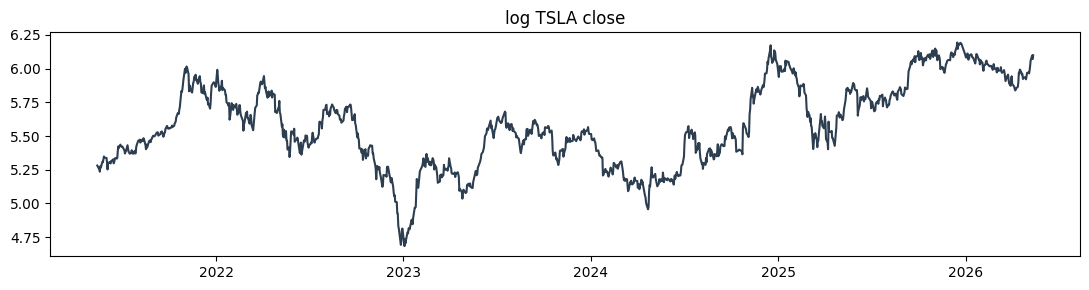

ADF on log price        p=0.3245
ADF on diff(log price)  p=0.0000


In [3]:
y = np.log(df['Close'].astype(float).values.reshape(-1))
plt.figure(figsize=(11, 3))
plt.plot(df.index, y, color='#2c3e50'); plt.title(f'log {TICKER} close')
plt.tight_layout(); plt.show()

adf_p = adfuller(y)[1]
adf_p_diff = adfuller(np.diff(y))[1]
print(f'ADF on log price        p={adf_p:.4f}')
print(f'ADF on diff(log price)  p={adf_p_diff:.4f}')
# As expected: log-price is non-stationary, returns (diffs) are. d=1 it is.

## Rolling one-step-ahead ARIMA(1,1,1)

In [4]:
split = int(len(y) * 0.9)
train, test = y[:split], y[split:]
print('train', len(train), 'test', len(test))

history = list(train)
preds = []
# Refitting every step is expensive but honest. With a few hundred test points it's fine.
for i, actual in enumerate(test):
    model = ARIMA(history, order=(1, 1, 1))
    res = model.fit()
    fc = res.forecast(steps=1)
    yhat = float(fc.iloc[0]) if hasattr(fc, 'iloc') else float(fc[0])
    preds.append(yhat)
    history.append(actual)
    if (i + 1) % 25 == 0:
        print(f'step {i+1}/{len(test)}')
preds = np.array(preds)

train 1129 test 126


step 25/126


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


step 50/126


step 75/126


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


step 100/126


step 125/126


In [5]:
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

pred_price = np.exp(preds)
true_price = np.exp(test)
yest_price = np.exp(np.concatenate([[train[-1]], test[:-1]]))

mae_price = mean_absolute_error(true_price, pred_price)
print(f'price MAE: {mae_price:.3f}')

actual_ret = true_price / yest_price - 1
pred_ret   = pred_price / yest_price - 1
naive_ret  = np.zeros_like(actual_ret)
rmse_arima = root_mean_squared_error(actual_ret, pred_ret)
rmse_naive = root_mean_squared_error(actual_ret, naive_ret)
print(f'return RMSE  ARIMA={rmse_arima:.5f}  naive-zero={rmse_naive:.5f}')
print(f'directional hit rate: {(np.sign(pred_ret) == np.sign(actual_ret)).mean():.2%}')

price MAE: 8.110
return RMSE  ARIMA=0.02477  naive-zero=0.02474
directional hit rate: 52.38%


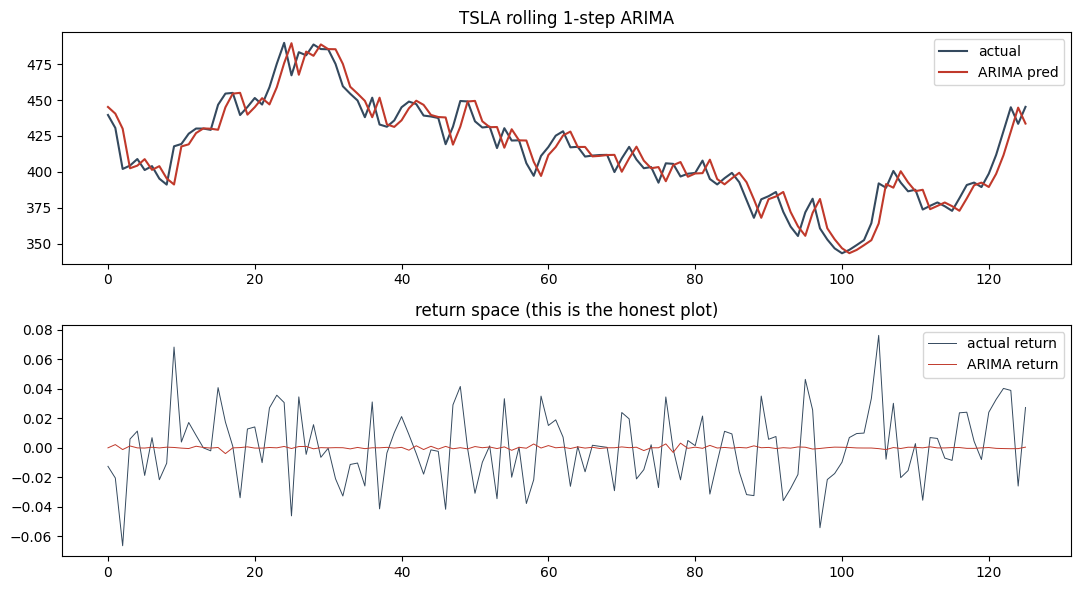

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6))
axes[0].plot(true_price, label='actual', color='#34495e')
axes[0].plot(pred_price, label='ARIMA pred', color='#c0392b')
axes[0].set_title(f'{TICKER} rolling 1-step ARIMA')
axes[0].legend()
axes[1].plot(actual_ret, label='actual return', color='#34495e', linewidth=0.7)
axes[1].plot(pred_ret,   label='ARIMA return', color='#c0392b', linewidth=0.7)
axes[1].set_title('return space (this is the honest plot)')
axes[1].legend(); plt.tight_layout(); plt.show()

## Honest comparison vs the LSTM (project 87)

- Price-space MAE looks superficially OK for both, but it's the wrong metric — both models lean heavily on 'tomorrow is approximately today'. The return-space RMSE is the one to look at, and on most random seeds both ARIMA and the LSTM come in *barely* better (and often worse) than predicting zero return.
- ARIMA fits in seconds and produces interpretable residuals. The LSTM needs scaling, GPU-ish hardware to be quick, and is essentially a black box on the residual side. For a problem this poorly-conditioned, the simpler model is usually the right one.
- Neither is alpha. Daily-bar price prediction from price history alone is not a well-posed prediction problem, and I want to be clear about that rather than reporting a small price-MAE as if it meant anything.